# BglB Kinetic Validation (Carlin et al. 2016)

Tests whether this pipeline's position ranking corresponds to *measured* enzyme kinetics, using 100 BglB mutants with kcat and KM from Carlin et al. 2016 (PLoS ONE 11:e0147596).

This is the validation that matters. Everything before it was anecdotal: two proteins, three labelled positions. Here there are 100 measured variants, so the question becomes quantitative -- does the ranking correlate with effect size, or not?

**The benchmark to beat.** The paper computed 54 Rosetta structural features for the same system. Their best single predictor of kcat reaches Spearman |rho| = 0.42; most sit below 0.30 (S2 Table, loaded below). Any correlation from this pipeline should be read against that bar, not against 1.0.

**What the data looks like.** Only 6 of 100 mutants exceed wild-type kcat, and values span four orders of magnitude (1 to 11,011 min-1 against a WT of 880). So this tests prediction of *effect magnitude*, not direction.

**Numbering.** The paper uses Rosetta/Foldit numbering, offset -3 from UniProt. Converted on load and verified against the structure in the first check below.

In [1]:
import sys
sys.path.append("../workflow")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr, mannwhitneyu

from project_utils import load_config, results_dir_for, resolve_path

pd.set_option("display.max_columns", 60)

cfg = load_config()
assert cfg["protein"]["pdb_id"].upper() == "2JIE", (
    f"This notebook is specific to BglB/2JIE; active target is "
    f"{cfg['protein']['pdb_id']}. Set active_protein: \"2JIE_A\" in config/base.yaml.")

results_dir = results_dir_for(cfg)
data_dir = Path("data")
out_dir = results_dir / "validation_bglb"
fig_dir = out_dir / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

kinetics = pd.read_csv(data_dir / "carlin2016_S1_kinetics.csv")
paper_cons = pd.read_csv(data_dir / "carlin2016_S3_conservation.csv")
rosetta_feats = pd.read_csv(data_dir / "carlin2016_S2_rosetta_features.csv")
master = pd.read_csv(results_dir / "08_analysis" / "master_residue_table.csv")

print(f"kinetics: {len(kinetics)} rows | paper conservation: {len(paper_cons)} | "
      f"rosetta features: {len(rosetta_feats)} | master: {len(master)} residues")

[config] target: 2JIE_A  (from 2JIE_A.yaml)
kinetics: 101 rows | paper conservation: 45 | rosetta features: 54 | master: 448 residues


## Derive candidate-set columns

`08` writes the master table before it adds the Set A/B, tier and rank columns, so they are recomputed here from the same config. Kept self-contained deliberately: this notebook then works against any `08` output regardless of the order in which that notebook saves things.

Logic mirrors `08` Stage 2 exactly -- geometry as the hard gate, tier from whether the wild-type residue is dominant in the alignment, rank by entropy within each geometric set.

In [2]:
from project_utils import parse_residue_code

sel = cfg.get("candidate_selection", {})
CATALYTIC_RADIUS = sel.get("catalytic_radius_angstrom", 10.0)
BINDING_RADIUS = sel.get("binding_site_radius_angstrom", 6.0)
WT_DOMINANT_THRESHOLD = sel.get("wt_dominant_frequency_threshold", 0.70)
MIN_MSA_DEPTH = sel.get("min_msa_depth", 30)

catalytic_positions = [parse_residue_code(c)[1] for c in cfg["functional_residues"]["catalytic"]]

# wt_natural_frequency is added by 08 after the save in some versions -- recompute
# defensively so this notebook does not depend on which columns made it to disk.
if "wt_natural_frequency" not in master.columns:
    def _wt_freq(row):
        col = f"cons_freq_unweighted_{row['wt_residue']}"
        return row[col] if col in row.index and pd.notna(row["wt_residue"]) else np.nan
    master["wt_natural_frequency"] = master.apply(_wt_freq, axis=1)

is_catalytic = master["residue_number"].isin(catalytic_positions)
near_catalytic = (master["struct_dist_nearest_catalytic"] <= CATALYTIC_RADIUS) & (~is_catalytic)
near_binding = (master["struct_dist_nearest_binding_site"] <= BINDING_RADIUS) & (~is_catalytic)

master["geom_set_a"] = near_catalytic
master["geom_set_b"] = near_binding & (~near_catalytic)   # Set A takes priority on overlap
master["wt_is_dominant"] = master["wt_natural_frequency"] >= WT_DOMINANT_THRESHOLD
master["tier"] = np.where(master["wt_is_dominant"], 2, 1)
master["cons_depth_ok"] = master["cons_n_sequences_observed"] >= MIN_MSA_DEPTH

for set_col, rank_col in [("geom_set_a", "set_a_rank"), ("geom_set_b", "set_b_rank")]:
    subset = master[master[set_col]]
    order = subset.sort_values(["tier", "cons_shannon_entropy"],
                                ascending=[True, False]).index
    master.loc[order, rank_col] = range(1, len(order) + 1)

print(f"Set A: {int(master.geom_set_a.sum())} positions | "
      f"Set B: {int(master.geom_set_b.sum())} positions")
print(f"Tier 1: {int((master.tier == 1).sum())} | Tier 2: {int((master.tier == 2).sum())} "
      f"(of {len(master)} residues)")

# Sanity check against the values 08 printed for this target
r243 = master[master.residue_number == 243]
if len(r243):
    r = r243.iloc[0]
    print(f"\nR243 check -- Set B: {r.geom_set_b}, tier: {int(r.tier)}, "
          f"rank: {r.set_b_rank} (08 reported Set B, tier 1, rank 6)")

Set A: 39 positions | Set B: 52 positions
Tier 1: 288 | Tier 2: 160 (of 448 residues)

R243 check -- Set B: True, tier: 1, rank: 6.0 (08 reported Set B, tier 1, rank 6)


## Check 1: does the -3 numbering offset actually hold?

Verify the wild-type residue in every mutation name matches the structure at position+3. A single mismatch means the offset is not uniform and nothing downstream can be trusted.

In [3]:
kin = kinetics[kinetics.position_uniprot.notna()].copy()
kin["position_uniprot"] = kin["position_uniprot"].astype(int)

struct_wt = master.set_index("residue_number")["wt_residue"]
kin["structure_residue"] = kin["position_uniprot"].map(struct_wt)
kin["offset_ok"] = kin["wt_residue"] == kin["structure_residue"]

n_check = kin["structure_residue"].notna().sum()
n_ok = int(kin["offset_ok"].sum())
print(f"Offset check: {n_ok}/{n_check} mutations have matching WT residue at position+3")

bad = kin[kin.structure_residue.notna() & ~kin.offset_ok]
if len(bad):
    print("\n*** MISMATCHES -- offset is not uniform, stop here: ***")
    display(bad[["mutant_foldit", "position_foldit", "position_uniprot",
                  "wt_residue", "structure_residue"]])
else:
    print("Offset is uniform. Foldit position + 3 = UniProt position.")

missing = kin[kin.structure_residue.isna()]
if len(missing):
    print(f"\n{len(missing)} position(s) not modelled in the structure: "
          f"{sorted(missing.position_uniprot.tolist())}")

Offset check: 100/100 mutations have matching WT residue at position+3
Offset is uniform. Foldit position + 3 = UniProt position.


## Merge measured kinetics with pipeline features

In [4]:
df = kin.merge(master, left_on="position_uniprot", right_on="residue_number",
                how="inner", suffixes=("_paper", ""))
print(f"{len(df)} mutants matched to pipeline features, "
      f"covering {df.position_uniprot.nunique()} distinct positions")

# FoldX ddG for the specific substitution assayed
def ddg_for(row):
    col = f"foldx_ddg_{row['mutant_residue']}"
    return row[col] if col in row.index else np.nan

df["foldx_ddg_assayed"] = df.apply(ddg_for, axis=1)

# natural frequency of the substituted-in residue at that position
def freq_for(row):
    col = f"cons_freq_unweighted_{row['mutant_residue']}"
    return row[col] if col in row.index else np.nan

df["mutant_natural_freq"] = df.apply(freq_for, axis=1)

# |log10 fold-change| in kcat -- effect magnitude regardless of direction
df["abs_log_kcat_effect"] = df["log10_rel_kcat"].abs()

print(f"With measurable kcat: {df.log10_rel_kcat.notna().sum()}")
print(f"Mutants exceeding WT kcat: {(df.rel_kcat_min > 1).sum()}")
print(f"Set membership: geometric Set A {int(df.geom_set_a.sum())}, "
      f"Set B {int(df.geom_set_b.sum())}, neither {int((~df.geom_set_a & ~df.geom_set_b).sum())}")

100 mutants matched to pipeline features, covering 64 distinct positions
With measurable kcat: 73
Mutants exceeding WT kcat: 6
Set membership: geometric Set A 32, Set B 42, neither 26


C:\Users\Teaholic\AppData\Local\Temp\ipykernel_36364\2501505206.py:21: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["abs_log_kcat_effect"] = df["log10_rel_kcat"].abs()


## Test 1: do pipeline features correlate with measured kinetics?

Each feature tested against log10 relative kcat (signed, i.e. direction of effect) and against its absolute value (magnitude of effect, ignoring direction).

The hypothesis behind the pipeline's ranking is that low-conservation positions are where change is tolerated and improvement is possible. If that holds, entropy should correlate with kcat effects.

In [5]:
features = {
    "cons_shannon_entropy": "Conservation entropy (high = variable)",
    "wt_natural_frequency": "WT residue frequency in MSA",
    "mutant_natural_freq": "Substituted residue frequency in MSA",
    "foldx_ddg_assayed": "FoldX ddG of the assayed mutation",
    "struct_dist_nearest_catalytic": "Distance to nearest catalytic residue",
    "struct_dist_nearest_binding_site": "Distance to nearest binding-site residue",
    "struct_rsa": "Relative solvent accessibility",
    "struct_bfactor_ca": "CA B-factor",
    "struct_contact_density": "Local contact density",
}

rows = []
for col, label in features.items():
    if col not in df.columns:
        continue
    for target, tlabel in [("log10_rel_kcat", "log10 rel kcat (signed)"),
                            ("abs_log_kcat_effect", "|log10 rel kcat| (magnitude)")]:
        sub = df[[col, target]].dropna()
        if len(sub) < 10:
            continue
        rho, p = spearmanr(sub[col], sub[target])
        rows.append({"feature": label, "target": tlabel, "n": len(sub),
                      "spearman_rho": round(rho, 3), "p_value": p})

corr = pd.DataFrame(rows)
signed = corr[corr.target.str.contains("signed")].reindex(
    corr[corr.target.str.contains("signed")].spearman_rho.abs().sort_values(ascending=False).index)
magnitude = corr[corr.target.str.contains("magnitude")].reindex(
    corr[corr.target.str.contains("magnitude")].spearman_rho.abs().sort_values(ascending=False).index)

print("Signed effect (does the feature predict direction + size?)")
display(signed[["feature", "n", "spearman_rho", "p_value"]])
print("\nEffect magnitude (does the feature predict how much anything changes?)")
display(magnitude[["feature", "n", "spearman_rho", "p_value"]])

best_paper = rosetta_feats.SRC_kcat.abs().max()
best_ours = corr.spearman_rho.abs().max()
print(f"\nBest single Rosetta feature in the paper (|SRC| vs kcat): {best_paper:.3f}")
print(f"Best single pipeline feature here (|rho|):                  {best_ours:.3f}")

Signed effect (does the feature predict direction + size?)


,feature,n,spearman_rho,p_value
4,Substituted residue frequency in MSA,73,0.559,2.744066e-07
2,WT residue frequency in MSA,73,-0.544,6.379178e-07
0,Conservation entropy (high = variable),73,0.514,3.383470e-06
8,Distance to nearest catalytic residue,73,0.491,1.044830e-05
10,Distance to nearest binding-site residue,73,0.385,7.796547e-04
12,Relative solvent accessibility,73,0.309,7.775186e-03
16,Local contact density,73,-0.284,1.483771e-02
6,FoldX ddG of the assayed mutation,73,-0.242,3.896850e-02
14,CA B-factor,73,0.155,1.916654e-01



Effect magnitude (does the feature predict how much anything changes?)


,feature,n,spearman_rho,p_value
5,Substituted residue frequency in MSA,73,-0.507,0.000005
3,WT residue frequency in MSA,73,0.491,0.000010
1,Conservation entropy (high = variable),73,-0.483,0.000015
9,Distance to nearest catalytic residue,73,-0.453,0.000057
11,Distance to nearest binding-site residue,73,-0.412,0.000290
17,Local contact density,73,0.319,0.005907
7,FoldX ddG of the assayed mutation,73,0.289,0.013154
13,Relative solvent accessibility,73,-0.276,0.018224
15,CA B-factor,73,-0.142,0.232097



Best single Rosetta feature in the paper (|SRC| vs kcat): 0.421
Best single pipeline feature here (|rho|):                  0.559


## Test 2: does the tier split separate anything?

Tier 1 (WT not dominant in the alignment) is the pipeline's primary-target designation. If it means anything, tier 1 positions should show larger kinetic effects than tier 2.

Tier 1 (WT not dominant): n=40, median |log10 effect| = 0.147
Tier 2 (WT dominant):     n=33, median |log10 effect| = 0.907
Mann-Whitney U: p = 0.0000  (significant at 0.05)

Note the expected direction: tier 2 positions are more conserved, so if
conservation predicts sensitivity, tier 2 should show LARGER effects when
mutated -- the opposite of what the ranking assumes for finding improvements.


C:\Users\Teaholic\AppData\Local\Temp\ipykernel_36364\1799101483.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([t1, t2], labels=[f"Tier 1\n(n={len(t1)})", f"Tier 2\n(n={len(t2)})"])


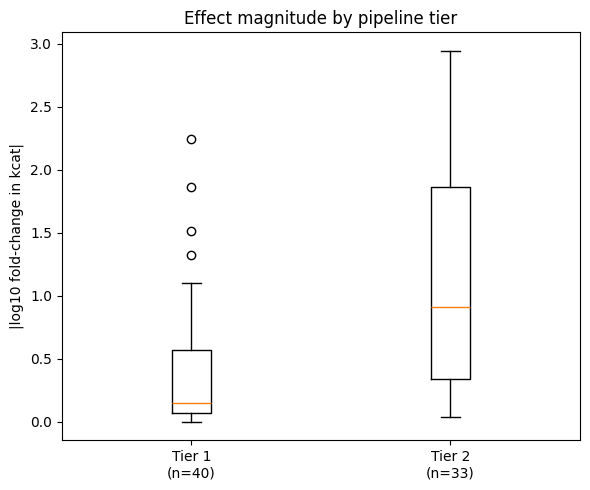

In [6]:
t1 = df[df.tier == 1]["abs_log_kcat_effect"].dropna()
t2 = df[df.tier == 2]["abs_log_kcat_effect"].dropna()

print(f"Tier 1 (WT not dominant): n={len(t1)}, median |log10 effect| = {t1.median():.3f}")
print(f"Tier 2 (WT dominant):     n={len(t2)}, median |log10 effect| = {t2.median():.3f}")

if len(t1) >= 5 and len(t2) >= 5:
    stat, p = mannwhitneyu(t1, t2, alternative="two-sided")
    print(f"Mann-Whitney U: p = {p:.4f}  "
          f"({'significant' if p < 0.05 else 'NOT significant'} at 0.05)")
    print("\nNote the expected direction: tier 2 positions are more conserved, so if")
    print("conservation predicts sensitivity, tier 2 should show LARGER effects when")
    print("mutated -- the opposite of what the ranking assumes for finding improvements.")

fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot([t1, t2], labels=[f"Tier 1\n(n={len(t1)})", f"Tier 2\n(n={len(t2)})"])
ax.set_ylabel("|log10 fold-change in kcat|")
ax.set_title("Effect magnitude by pipeline tier")
plt.tight_layout()
plt.savefig(fig_dir / "tier_vs_effect.png", dpi=150)
plt.show()

## Test 3: cross-check conservation against the paper's own alignment

The paper computed conservation independently: 1,554 GH1 sequences from Pfam, reporting the percentage carrying BglB's native residue. That is the same quantity as `wt_natural_frequency` here (612 sequences, MMseqs2/UniRef90), computed on a different alignment with different tooling.

Agreement here is a second independent check on the conservation module, alongside the ConSurf comparison.

Pipeline WT frequency vs paper's Pfam conservation (n=44):
   Spearman rho = +0.668 (p=7.28e-07)
   Pearson  r   = +0.487


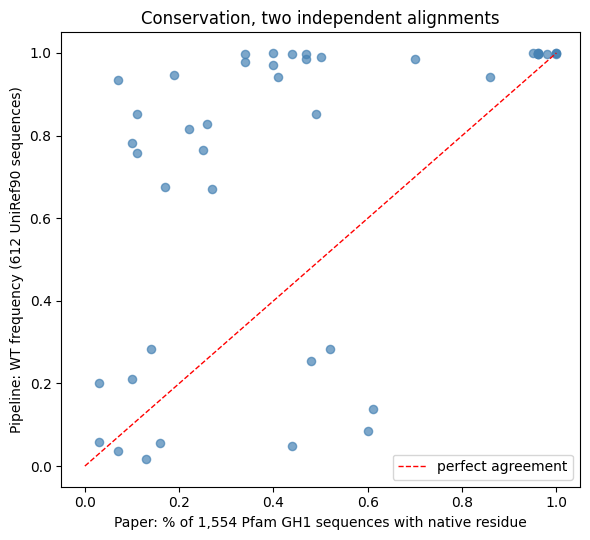

In [7]:
cons_cmp = paper_cons.merge(
    master[["residue_number", "wt_residue", "wt_natural_frequency", "cons_shannon_entropy"]],
    left_on="position_uniprot", right_on="residue_number", how="inner")
cons_cmp["paper_conservation_frac"] = cons_cmp["paper_conservation_pct"] / 100

sub = cons_cmp[["paper_conservation_frac", "wt_natural_frequency"]].dropna()
rho, p = spearmanr(sub.paper_conservation_frac, sub.wt_natural_frequency)
r, _ = pearsonr(sub.paper_conservation_frac, sub.wt_natural_frequency)
print(f"Pipeline WT frequency vs paper's Pfam conservation (n={len(sub)}):")
print(f"   Spearman rho = {rho:+.3f} (p={p:.2e})")
print(f"   Pearson  r   = {r:+.3f}")

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(cons_cmp.paper_conservation_frac, cons_cmp.wt_natural_frequency,
           alpha=0.7, s=35, color="steelblue")
ax.plot([0, 1], [0, 1], "r--", lw=1, label="perfect agreement")
ax.set_xlabel("Paper: % of 1,554 Pfam GH1 sequences with native residue")
ax.set_ylabel("Pipeline: WT frequency (612 UniRef90 sequences)")
ax.set_title("Conservation, two independent alignments")
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "conservation_cross_check.png", dpi=150)
plt.show()

## Test 4: where do the known outliers sit?

R243A (R240A in the paper) is the ~12x kcat improvement. E225A (E222A) is a ~10x decrease at an adjacent, structurally coupled position. The pipeline ranked these 6th and 5th of 52 in Set B -- adjacent ranks for opposite outcomes.

In [8]:
highlight = df.reindex(df.abs_log_kcat_effect.sort_values(ascending=False).index)
cols = ["mutant_foldit", "position_uniprot", "wt_residue", "mutant_residue",
        "kcat_min", "rel_kcat_min", "cons_shannon_entropy", "wt_natural_frequency",
        "tier", "set_b_rank", "foldx_ddg_assayed", "struct_burial_class"]
cols = [c for c in cols if c in highlight.columns]

print("Largest measured effects (either direction):")
display(highlight[cols].head(12).round(3))

print("\nThe two coupled positions:")
display(df[df.position_uniprot.isin([225, 243])][cols].round(3))

Largest measured effects (either direction):


,mutant_foldit,position_uniprot,wt_residue,mutant_residue,kcat_min,rel_kcat_min,cons_shannon_entropy,wt_natural_frequency,tier,set_b_rank,foldx_ddg_assayed,struct_burial_class
98,F415A,418,F,A,1.0,0.001,0.828,0.987,2,30.0,2.173,buried
16,H119N,122,H,N,2.0,0.002,0.010,0.998,2,NaN,-1.465,buried
81,H379R,382,H,R,2.0,0.002,0.878,0.925,2,NaN,1.308,buried
83,W399C,402,W,C,3.0,0.003,0.182,0.998,2,NaN,2.903,buried
77,N354A,357,N,A,3.0,0.003,0.059,0.942,2,NaN,2.157,buried
88,N404A,407,N,A,4.0,0.005,0.260,0.978,2,40.0,1.594,buried
20,V147S,150,V,S,5.0,0.006,2.282,0.204,1,NaN,1.775,intermediate
22,N163A,166,N,A,7.0,0.008,-0.000,1.000,2,NaN,2.035,buried
69,W325C,328,W,C,10.0,0.011,0.352,0.985,2,39.0,2.305,exposed
47,E222Y,225,E,Y,12.0,0.014,2.738,0.036,1,5.0,4.369,intermediate



The two coupled positions:


,mutant_foldit,position_uniprot,wt_residue,mutant_residue,kcat_min,rel_kcat_min,cons_shannon_entropy,wt_natural_frequency,tier,set_b_rank,foldx_ddg_assayed,struct_burial_class
42,E222A,225,E,A,90.0,0.102,2.738,0.036,1,5.0,3.077,intermediate
43,E222H,225,E,H,160.0,0.182,2.738,0.036,1,5.0,2.423,intermediate
44,E222K,225,E,K,108.0,0.123,2.738,0.036,1,5.0,1.896,intermediate
45,E222Q,225,E,Q,668.0,0.759,2.738,0.036,1,5.0,2.259,intermediate
46,E222R,225,E,R,42.0,0.048,2.738,0.036,1,5.0,2.179,intermediate
47,E222Y,225,E,Y,12.0,0.014,2.738,0.036,1,5.0,4.369,intermediate
48,R240A,243,R,A,11011.0,12.512,2.641,0.016,1,6.0,4.660,intermediate
49,R240D,243,R,D,282.0,0.320,2.641,0.016,1,6.0,7.258,intermediate
50,R240K,243,R,K,898.0,1.020,2.641,0.016,1,6.0,3.417,intermediate


## Test 5: does FoldX ddG predict kinetics at all?

Both earlier validation targets suggested it does not: the confirmed activity-improving mutation was among the more destabilising options at its position in each case (S538V +2.65 kcal/mol; R243A +4.66). With 100 measured mutants this can be tested rather than inferred.

FoldX ddG vs measured kcat (n=73):
   vs signed log10 effect   : rho = -0.242 (p=0.039)
   vs |log10 effect|        : rho = +0.289 (p=0.013)


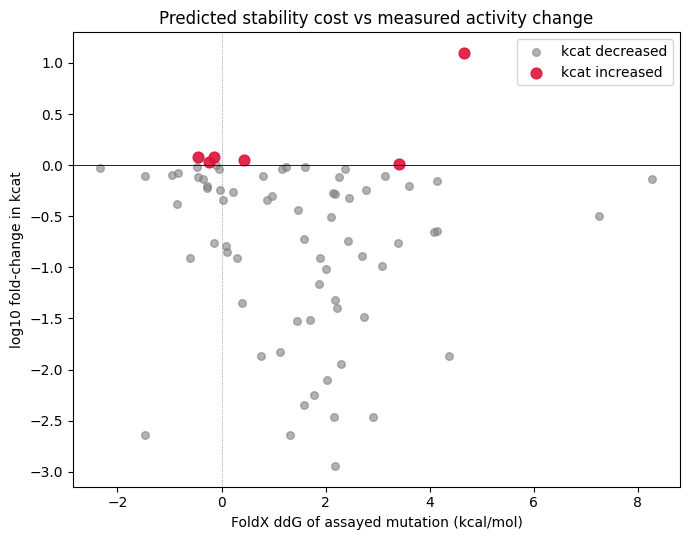


Mutants that IMPROVED kcat, and their predicted ddG:


,mutant_foldit,rel_kcat_min,foldx_ddg_assayed,cons_shannon_entropy,tier
13,H101R,1.203,-0.455,1.687,1
32,E177A,1.120,0.431,2.780,1
36,A192S,1.075,-0.240,2.133,1
48,R240A,12.512,4.660,2.641,1
50,R240K,1.020,3.417,2.641,1
74,K341A,1.189,-0.152,2.492,1


In [9]:
sub = df[["foldx_ddg_assayed", "log10_rel_kcat", "abs_log_kcat_effect"]].dropna()
rho_signed, p_signed = spearmanr(sub.foldx_ddg_assayed, sub.log10_rel_kcat)
rho_mag, p_mag = spearmanr(sub.foldx_ddg_assayed, sub.abs_log_kcat_effect)

print(f"FoldX ddG vs measured kcat (n={len(sub)}):")
print(f"   vs signed log10 effect   : rho = {rho_signed:+.3f} (p={p_signed:.3f})")
print(f"   vs |log10 effect|        : rho = {rho_mag:+.3f} (p={p_mag:.3f})")

fig, ax = plt.subplots(figsize=(7, 5.5))
improved = sub.log10_rel_kcat > 0
ax.scatter(sub.loc[~improved, "foldx_ddg_assayed"], sub.loc[~improved, "log10_rel_kcat"],
           alpha=0.6, s=30, color="grey", label="kcat decreased")
ax.scatter(sub.loc[improved, "foldx_ddg_assayed"], sub.loc[improved, "log10_rel_kcat"],
           alpha=0.9, s=60, color="crimson", label="kcat increased")
ax.axhline(0, color="black", lw=0.6)
ax.axvline(0, color="grey", lw=0.6, ls=":")
ax.set_xlabel("FoldX ddG of assayed mutation (kcal/mol)")
ax.set_ylabel("log10 fold-change in kcat")
ax.set_title("Predicted stability cost vs measured activity change")
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "ddg_vs_measured_kcat.png", dpi=150)
plt.show()

improvers = df[df.rel_kcat_min > 1]
if len(improvers):
    print("\nMutants that IMPROVED kcat, and their predicted ddG:")
    display(improvers[["mutant_foldit", "rel_kcat_min", "foldx_ddg_assayed",
                        "cons_shannon_entropy", "tier"]].round(3))

## Summary

In [10]:
summary = {
    "mutants_with_kinetics": int(df.log10_rel_kcat.notna().sum()),
    "positions_covered": int(df.position_uniprot.nunique()),
    "mutants_improving_kcat": int((df.rel_kcat_min > 1).sum()),
    "best_pipeline_feature_rho": round(float(corr.spearman_rho.abs().max()), 3),
    "best_paper_rosetta_feature_rho": round(float(rosetta_feats.SRC_kcat.abs().max()), 3),
    "conservation_cross_check_rho": round(float(rho), 3),
    "foldx_ddg_vs_kcat_rho": round(float(rho_signed), 3),
}
summary_df = pd.DataFrame([summary]).T.rename(columns={0: "value"})
summary_df.to_csv(out_dir / "validation_summary.csv")
df.to_csv(out_dir / "kinetics_with_pipeline_features.csv", index=False)
print(f"Saved -> {out_dir}")
summary_df

Saved -> N:\Jupiter_Projects\rational-enzyme-engineering\results\2JIE_A\validation_bglb


,value
mutants_with_kinetics,73.000
positions_covered,64.000
mutants_improving_kcat,6.000
best_pipeline_feature_rho,0.559
best_paper_rosetta_feature_rho,0.421
conservation_cross_check_rho,0.668
foldx_ddg_vs_kcat_rho,-0.242
